# CSDA Vendor Specs database: QA, update loop and constellation comparison

Reads the **Vendor Specs** tab of the CSDA specs Google Sheet live and:

1. **Applies edits and keeps a record**: every changed cell (before, after, source, date) goes into `specs/edits_log.csv`;
   all results below use the edited values.
2. **Checks columns A–AS** automatically (shifted cells, dates, vocabularies, inconsistent pairs such as off-nadir vs nadir
   GSD or orbit period vs altitude) and lists errors suspected from outside knowledge that need a source.
3. **Shows what is missing** (filled / empty grid of A–AS by sensor).
4. **Compares constellations**: image footprint (swath), GSD and number of bands, and **revisit time** at 0°, 40° and 60°
   latitude, simulated from the orbits.
5. **Writes an interactive dashboard** (`html/vendor_specs.html`): hover any constellation for its specs and open flags.
6. **Supports the update loop** with vendor documents on SharePoint: builds a NASA Chat prompt that extracts A–AS for one
   constellation with page citations, then diffs the answer against the sheet.

**Update plan** (each step uses a section below)

| Step | What | Where |
|---|---|---|
| 1. Define the fields | Settle what each A–AS field means. **Decided 2 Nov 2026: *Total Bands (MS)* counts the pan band.** Revisit is now simulated (section 6) rather than read from the sheet; the sheet's *Revisit Time* needs a definition or can go. Still open: GSD native or product | data dictionary, e.g. on the *SME needs* tab |
| 2. Fix structural errors | Shifted cells, swapped dates, text in number fields, status vocabulary | section 3 table (`vendor_specs_qa.csv`) |
| 3. Verify against sources | Priority: vendors CSDA is evaluating, then government references. Public specs: CSDA vendor pages (science.nasa.gov), vendor datasheets, USGS / ESA. SharePoint documents: NASA Chat with the section 8 prompt. Fill **Reference** for every row (25 of 84 have one) | sections 2, 8 |
| 4. Fill the gaps | Section 4 grid shows empty fields; decide which columns to keep (X, Y, AI, AR, AS are empty for every sensor) | section 4 |
| 5. Record and re-run | Every change goes through the edit record (section 2); QA count falls, plots refresh from the live sheet | this notebook |

**Data handling.** Vendor material on SharePoint may be CUI (e.g. the Airbus TEM). Keep it in NASA Chat; bring back only
values cleared for the database.

Library: `lib/vendor_specs.py`.

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import vendor_specs as vs
importlib.reload(vs)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 70)

## Parameters

In [2]:
SHEET_ID = vs.SHEET_ID                 # 'NASA CSDA ... Vendor Specs' Google Sheet (shared 'anyone with the link')
GID = vs.GID['Vendor Specs']

# Constellations to compare: 'current' = operational / constellation / limited (or no status yet); 'all' = every row
SCOPE = 'current'
SECTORS = ['Commercial', 'Government']

# Display names for constellation groups (group name built from the sheet -> name on the plots)
LABELS = {'NewSat Mark I': 'Satellogic Mark I', 'NewSat Mark II': 'Satellogic Mark II', 'NewSat Mark III': 'Satellogic Mark III',
          'NewSat Mark IV': 'Satellogic Mark IV', 'NewSat Mark V': 'Satellogic Mark V',
          'GEISAT GEISAT-P': 'Satlantis GEISAT-P', 'GEISAT HORACIO': 'Satlantis HORACIO',
          'OSK GHOSt-3/GHOSt-4/GHOSt-5': 'OSK GHOSt', 'OSK GHOSt-6': 'OSK GHOSt-6',
          'ImageSat EROS-C2/EROS-C3': 'ImageSat EROS-C2/C3', 'PleiadesNeo': 'Pléiades Neo', 'Pleiades': 'Pléiades',
          'HydroSat': 'Hydrosat VanZyl', 'Kuva': 'Kuva Hyperfield', 'FireSat': 'FireSat (proto)',
          'Firefly': 'Pixxel Firefly'}

# Edit record (one row per changed cell, kept in the repo) and the batches of edits it is built from
EDIT_LOG = '/home/pmontesa/code/csda_summaries/specs/edits_log.csv'
APPS_SCRIPT = '/home/pmontesa/code/csda_summaries/specs/apply_edits.gs'   # writes the edits into the Google Sheet
EDIT_BATCHES = [  # (proposed-edits CSV, batch name, date); a batch already in the record is not added again
    ('/home/pmontesa/code/csda_summaries/specs/public_check_2026-11-02.csv', 'public_check_2026-11-02', '2026-11-02'),
    ('/home/pmontesa/code/csda_summaries/specs/public_check_2026-11-03_pixxel.csv', 'pixxel_firefly_2026-11-03', '2026-11-03'),   # 3 new rows
    ('/home/pmontesa/code/csda_summaries/specs/public_check_2026-11-06_enmap.csv', 'enmap_2026-11-06', '2026-11-06'),   # 1 new row
]

# Revisit (section 6): simulated from orbit, swath and pointing at 0, 40 and 60 deg latitude
REVISIT_CAP_DEG = 20      # view-angle limit (deg off nadir) for the radiometric-quality view
SUN_MIN_DEG = 10          # a pass counts only with the sun at least this high at the site
REVISIT_CSV = '/home/pmontesa/code/csda_summaries/specs/revisit_estimates.csv'    # record of the values put in the sheet
REVISIT_SCRIPT = '/home/pmontesa/code/csda_summaries/specs/write_revisit.gs'     # writes them into the Google Sheet

OUT_DIR = Path('vendor_specs_out')     # QA table and figures (PNG)
DASHBOARD = Path('../html/vendor_specs.html')   # interactive dashboard (GitHub Pages: html/vendor_specs.html)
DPI = 200
OUT_DIR.mkdir(exist_ok=True)

## 1. Load the sheet

Text as entered (no type conversion); `sheet_row` is the row number in the sheet, `label` = constellation + sensor.

In [3]:
sheet = vs.load(vs.csv_url(SHEET_ID, GID))   # as in the Google Sheet now
core = vs.core_fields(sheet)
print(f"{len(sheet)} sensors, {len(sheet.columns) - 2} columns; core fields A-AS: {len(core)} "
      f"({core[0]} ... {core[-1]})")
sheet[['sheet_row', 'label', 'Affiliation', 'Sector', 'Mission Status', 'Launch Date']].head()

87 sensors, 102 columns; core fields A-AS: 45 (Sensor Name ... Radiometric Temporal Stability (%))


,sheet_row,label,Affiliation,Sector,Mission Status,Launch Date
0,2,PleiadesNeo PNEO3,Airbus,Commercial,Operational,2021-04-28
1,3,PleiadesNeo PNEO4,Airbus,Commercial,Operational,2021-08-16
2,4,Pleiades PHR1A,Airbus,Commercial,Operational,2011-12-17
3,5,Pleiades PHR1B,Airbus,Commercial,Operational,2012-12-02
4,6,SPOT SPOT6,Airbus,Commercial,Operational,2012-09-09


## 2. Edits: record and apply

Every change to the database is kept in **`specs/edits_log.csv`**, one row per sheet cell: `edit_id`, `date`, `batch`,
`cell` (e.g. `CI2`), sensor, field, `before`, `after`, `source`, `source_url`, `note`. Batches are appended, never
rewritten, so the file is the full history.

Batch `public_check_2026-11-02`: the public-source check of 2 Nov 2026 (`specs/public_check_2026-11-02.csv`, one row per
field and row span). Sources, in order of preference: the **CSDA vendor pages** on science.nasa.gov, vendor / agency
pages, then secondary sites; *computed* = derived from other fields. Not covered yet: launch dates, masses and altitudes
for most vendors, EarthDaily, government sensors other than Landsat 7, and most columns from AM (bit depth) on.

The edits are applied on top of the sheet as read now (`raw` below); `status` per cell:

| status | meaning |
|---|---|
| applied (not yet in sheet) | the sheet still has the old value; the new one is used here. Copy it into the sheet (cell address in `cell`) |
| in sheet | the sheet already has the new value |
| skipped: sheet changed | the sheet has a third value (edited since): the sheet value is used; review the record |

**Copy into the sheet**: the cell below also writes `specs/apply_edits.gs`, a Google Apps Script for the edits not yet in
the sheet. In the spreadsheet: Extensions > Apps Script, paste, save; run `previewEdits` (changes nothing, logs what would
change), then `applyEdits`. It writes a cell only if the column header matches the field and the cell still shows the
`before` value, skips (and lists) a cell the sheet rejects, e.g. by data validation, and lists every edit once in the
sheet tab *Edit log*. Re-run this notebook afterwards: the
status becomes *in sheet*.

To add edits later: write a CSV like the public-check one, add it to `EDIT_BATCHES`, re-run.

In [4]:
for path, batch, date in EDIT_BATCHES:
    log = vs.record_edits(sheet, vs.load_edits(path), EDIT_LOG, batch=batch, date=date)
raw, log = vs.apply_edits(sheet, vs.load_edit_log(EDIT_LOG))
print(f"{len(log)} cell edits in {EDIT_LOG}:", log.status.value_counts().to_dict())
print("by source:", log.source.value_counts().to_dict())
# Apps Script that writes the edits not yet in the sheet into it (paste into Extensions > Apps Script; see its header)
if (log.status == 'applied (not yet in sheet)').any():
    print('wrote', vs.apps_script(log, APPS_SCRIPT))
log[['edit_id', 'date', 'cell', 'label', 'field', 'before', 'after', 'status', 'source']]

246 cell edits in /home/pmontesa/code/csda_summaries/specs/edits_log.csv: {'in sheet': 219, 'applied (not yet in sheet)': 27}
by source: {'CSDA vendor page': 161, 'computed': 32, 'agency page': 26, 'secondary': 13, 'vendor page': 13, 'definition (MS counts pan)': 1}
wrote /panfs/ccds02/home/pmontesa/code/csda_summaries/specs/apply_edits.gs


,edit_id,date,cell,label,field,before,after,status,source
0,1,2026-11-02,CI2,PleiadesNeo PNEO3,Total Bands (MS),6,7,in sheet,CSDA vendor page
1,2,2026-11-02,CI3,PleiadesNeo PNEO4,Total Bands (MS),6,7,in sheet,CSDA vendor page
2,3,2026-11-02,CJ2,PleiadesNeo PNEO3,Total Bands,6,7,in sheet,CSDA vendor page
3,4,2026-11-02,CJ3,PleiadesNeo PNEO4,Total Bands,6,7,in sheet,CSDA vendor page
4,5,2026-11-02,AV2,PleiadesNeo PNEO3,Coastal Min (nm),(empty),400,in sheet,CSDA vendor page
...,...,...,...,...,...,...,...,...,...
241,325,2026-11-06,CG89,EnMAP HSI,Hypersp Max (µm),(empty),2450,applied (not yet in sheet),agency page
242,326,2026-11-06,CH89,EnMAP HSI,Spectral Resolution (µm),(empty),0.0065-0.01,applied (not yet in sheet),agency page
243,327,2026-11-06,CI89,EnMAP HSI,Total Bands (MS),(empty),224,applied (not yet in sheet),agency page
244,328,2026-11-06,CJ89,EnMAP HSI,Total Bands,(empty),224,applied (not yet in sheet),agency page


## 3. Automated checks (columns A–AS and band counts)

Run on the edited values. One row per suspect cell: `column` is the sheet column letter. The checks find structural problems; they cannot say a
value is right. Saved to `vendor_specs_qa.csv` for working through in the sheet.

| check | meaning |
|---|---|
| shifted cells? | text where Yes / No belongs (or a number): cells from there right are probably one or more columns off |
| off-nadir finer than nadir | off-nadir GSD minimum below the nadir GSD |
| period vs altitude | orbit period differs > 1.5 min from a circular orbit at that altitude |
| MS count leaves out pan | rule: *Total Bands (MS)* counts pan; the row has a pan range but the count equals the MS ranges only |
| band count vs band ranges | *Total Bands (MS)* differs from the filled band ranges (16 named slots; sensors with more bands skipped) |
| size class vs mass | class does not match the mass ranges (Nano < 10 kg ... Large > 1000 kg) |
| status vs launch / end date | e.g. Planned with a past launch date, Constellation with a past End Date |
| not in vocabulary, date format, not a number, missing | entry does not follow the field's format |

In [5]:
issues = vs.qa_checks(raw)
issues.to_csv(OUT_DIR / 'vendor_specs_qa.csv', index=False)
print(f"{len(issues)} suspect cells in {issues.sheet_row.nunique()} of {len(raw)} rows -> {OUT_DIR / 'vendor_specs_qa.csv'}")
issues.groupby('check').agg(cells=('sheet_row', 'size'), rows=('sheet_row', 'nunique'),
                            columns=('column', lambda c: ', '.join(sorted(set(c))))).sort_values('cells', ascending=False)

45 suspect cells in 33 of 88 rows -> vendor_specs_out/vendor_specs_qa.csv


,cells,rows,columns
check,,,
band count vs band ranges,10,10,CI
missing,6,6,"T, U"
size class vs mass,5,5,K
shifted cells?,5,3,"AK, AL"
MS count leaves out pan,3,3,CI
not a number,3,3,AJ
period vs altitude,2,2,O
date format,2,2,"C, D"
off-nadir finer than nadir,2,2,AF


In [6]:
issues

,sheet_row,label,column,field,value,check,detail
0,10,Global Gen 3,CI,Total Bands (MS),4,MS count leaves out pan,4 MS band ranges + pan = 5; Total Bands (MS) = 4 (rule: count pan)
1,11,Aurora EDA,O,Orbit Period (min),95,period vs altitude,600 km gives 96.7 min (circular orbit)
2,12,Envisat MERIS,CI,Total Bands (MS),15,band count vs band ranges,"8 MS band ranges filled = 8, Total Bands (MS) = 15"
3,13,Sentinel 2A (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
4,14,Sentinel 2B (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
5,15,Sentinel 2C (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
6,16,Sentinel 2D (MSI),CI,Total Bands (MS),13,band count vs band ranges,"11 MS band ranges filled = 11, Total Bands (MS) = 13"
7,20,Sentinel 3D (OLCI/SLSTR),J,Mission Status,Planned,status vs launch,Planned but the launch date has passed
8,21,PROBA-V Vegetation,K,Satellite Size Class,Large,size class vs mass,138 kg is Mini
9,22,HydroSat VanZyl-1,CI,Total Bands (MS),7,band count vs band ranges,"8 MS band ranges filled = 8, Total Bands (MS) = 7"


## 4. What is filled in

Dark = the field has a value. The numbers on top are the share of sensors with the field filled.

Least filled sensors: GHOSt GHOSt-6 (24%), ImageSat Runner-1 (33%), ImageSat EROS-C2 (36%), ImageSat EROS-B (36%), HydroSat VanZyl-2 (38%), ImageSat EROS-C3 (38%), ImageSat EROS-A (38%), HydroSat VanZyl-1 (40%), NewSat Mark II (40%), GHOSt GHOSt-5 (40%)


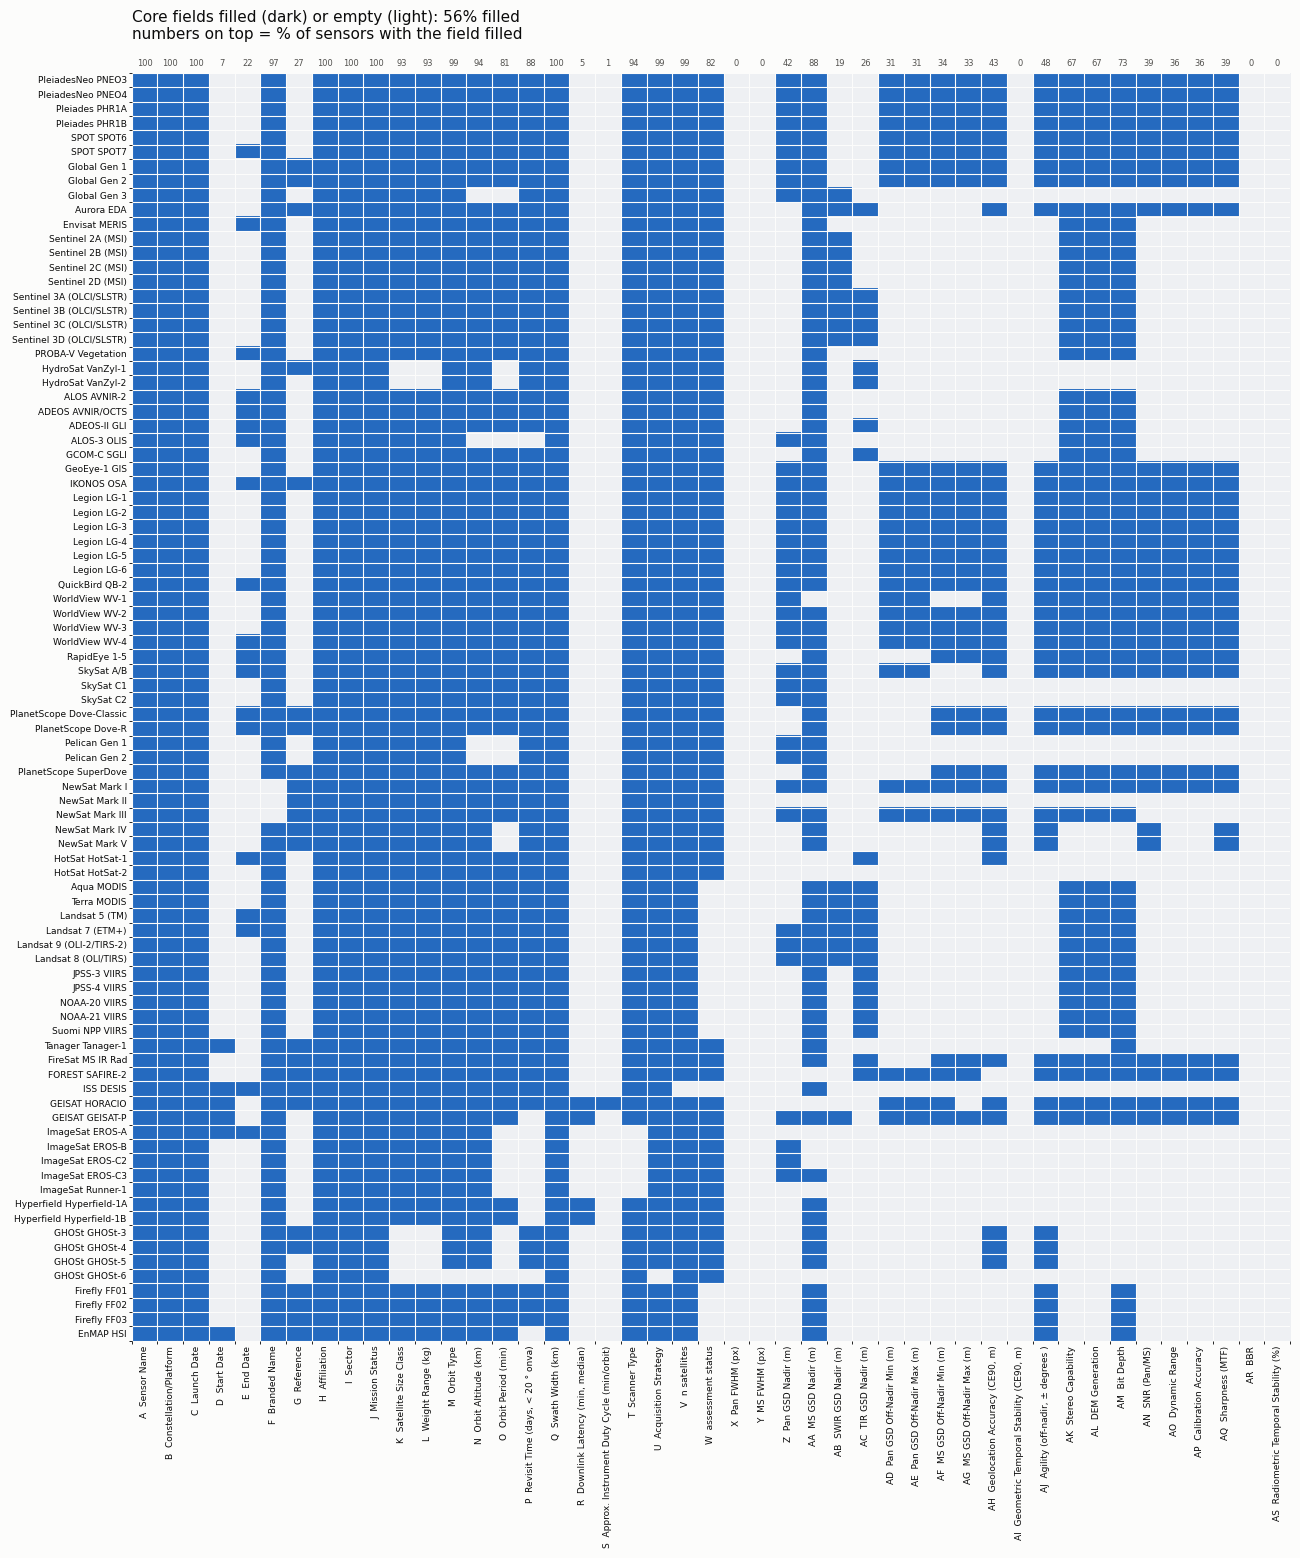

In [7]:
fig = vs.plot_completeness(raw)
fig.savefig(OUT_DIR / 'vendor_specs_completeness.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())
filled = vs.completeness(raw)
print('Least filled sensors:', ', '.join(f"{k} ({v:.0%})" for k, v in filled.mean(axis=1).sort_values().head(10).items()))

## 5. Constellations compared: footprint, GSD, number of bands

Sensors of one data owner with the same GSD, swath and band count are merged into one group (e.g. Legion LG-1 to LG-6,
VIIRS on four platforms). Numbers are parsed from the text (`~97` -> 97, ranges -> first value). Band counts of rows with
shifted cells are not used. **\*** on a plot = one of the plotted values (GSD, swath, band count) is still flagged by the
checks in section 3: check it before quoting it. A **black ring** marks a constellation with a pan band.

In [8]:
shifted = sorted(issues.loc[issues.check == 'shifted cells?', 'sheet_row'].unique())
all_groups = vs.constellations(raw, labels=LABELS, drop_rows=shifted)
groups = all_groups
if SCOPE == 'current':
    groups = groups[groups.current]
groups = groups[groups.sector.isin(SECTORS)].reset_index(drop=True)

# Groups with a plotted value still flagged by the section 3 checks
plotted = ['Pan GSD Nadir (m)', 'MS GSD Nadir (m)', 'Swath Width (km)', 'Total Bands (MS)']
flag_rows = set(issues.loc[issues.field.isin(plotted), 'sheet_row'])
FLAGGED = [g for g, rows in zip(groups.group, groups.sheet_rows)
           if flag_rows & {int(r) for r in rows.split(', ')}]
print(f"{len(groups)} constellation groups ({SCOPE}); flagged: {', '.join(FLAGGED)}")
groups[['group', 'affiliation', 'sector', 'sensors', 'status', 'pan_gsd', 'ms_gsd', 'swath_km', 'ms_bands',
        'total_bands', 'revisit_days', 'ce90_m', 'scanner']]

44 constellation groups (current); flagged: BlackSky Gen 3, WorldView-3, Satlantis GEISAT-P, FireSat (proto), Hydrosat VanZyl, Sentinel-2


,group,affiliation,sector,sensors,status,pan_gsd,ms_gsd,swath_km,ms_bands,total_bands,revisit_days,ce90_m,scanner
0,Pelican Gen 2,Planet Labs,Commercial,Gen 2,Constellation,0.30,0.30,6.0,7.0,NaN,0.5,NaN,Pushbroom
1,Pelican Gen 1,Planet Labs,Commercial,Gen 1,Constellation,0.50,0.50,8.0,7.0,NaN,0.5,NaN,Pushbroom
2,Satellogic Mark V,Satellogic,Commercial,Mark V,Constellation,NaN,0.70,6.5,4.0,4.0,1.0,30.0,Pushframe
3,SkySat C2,Planet Labs,Commercial,C2,Constellation,0.57,0.75,5.5,5.0,5.0,1.0,NaN,Pushframe
4,ImageSat EROS-C3,ImageSat,Commercial,EROS-C3,Operational,0.43,0.86,12.5,5.0,NaN,NaN,NaN,NaN
5,Satellogic Mark IV,Satellogic,Commercial,Mark IV,Constellation,NaN,0.99,5.0,4.0,4.0,1.0,30.0,Pushframe
6,SkySat A/B,Planet Labs,Commercial,A/B,Constellation,0.86,1.00,8.0,5.0,5.0,1.0,30.0,Frame/Video
7,SkySat C1,Planet Labs,Commercial,C1,Constellation,0.72,1.00,5.9,5.0,5.0,1.0,NaN,Pushframe
8,Satellogic Mark I,Satellogic,Commercial,Mark I,Constellation,1.00,1.00,5.0,4.0,4.0,0.5,10.0,Pushbroom
9,Satellogic Mark III,Satellogic,Commercial,Mark III,Constellation,1.00,1.00,5.0,NaN,NaN,0.5,30.0,Pushbroom


### Footprint vs. detail

Each constellation by its multispectral GSD (x) and swath width (y), both log scales; marker size = number of bands,
color = sector. The dashed diagonals count **pixels across the swath** (swath / GSD): most sensors, from 30 cm VHR to
VIIRS, sit between about 3,000 and 30,000 pixels across, so a finer GSD buys a proportionally narrower footprint.

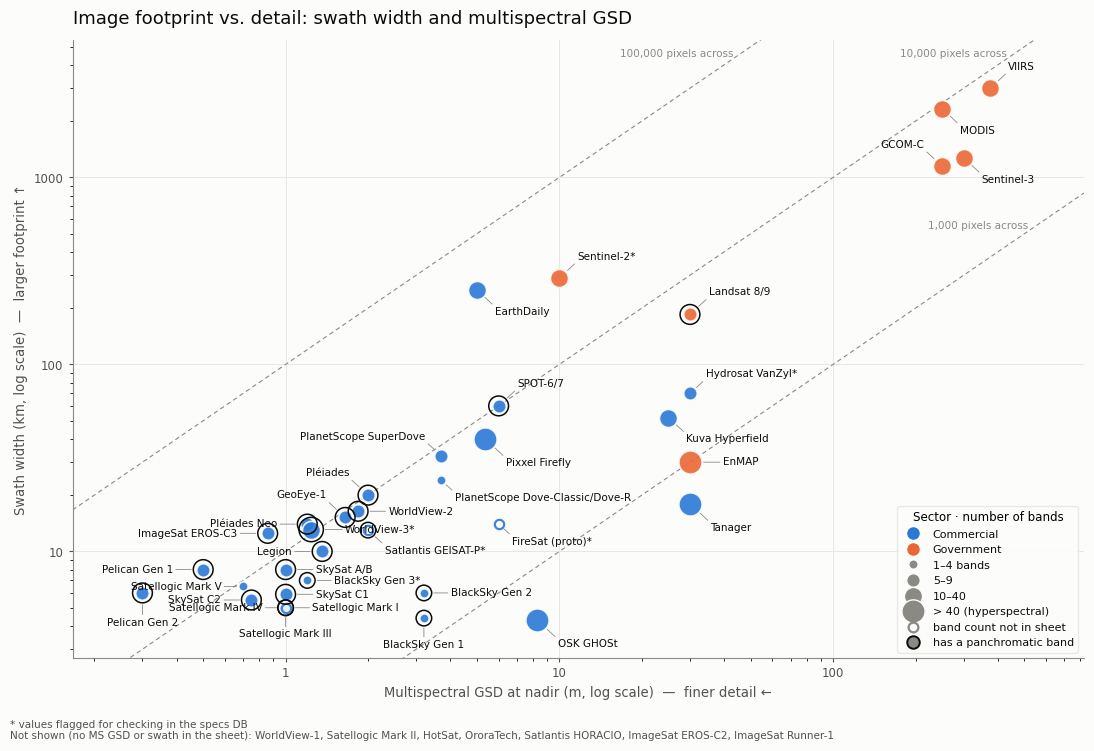

In [9]:
fig = vs.plot_gsd_swath(groups, flagged=FLAGGED)
fig.savefig(OUT_DIR / 'specs_gsd_vs_swath.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())

### Key specs side by side

One row per constellation, sorted by multispectral GSD; three aligned panels with their own (log) axes: GSD (filled =
multispectral, open = panchromatic), swath width, number of bands.

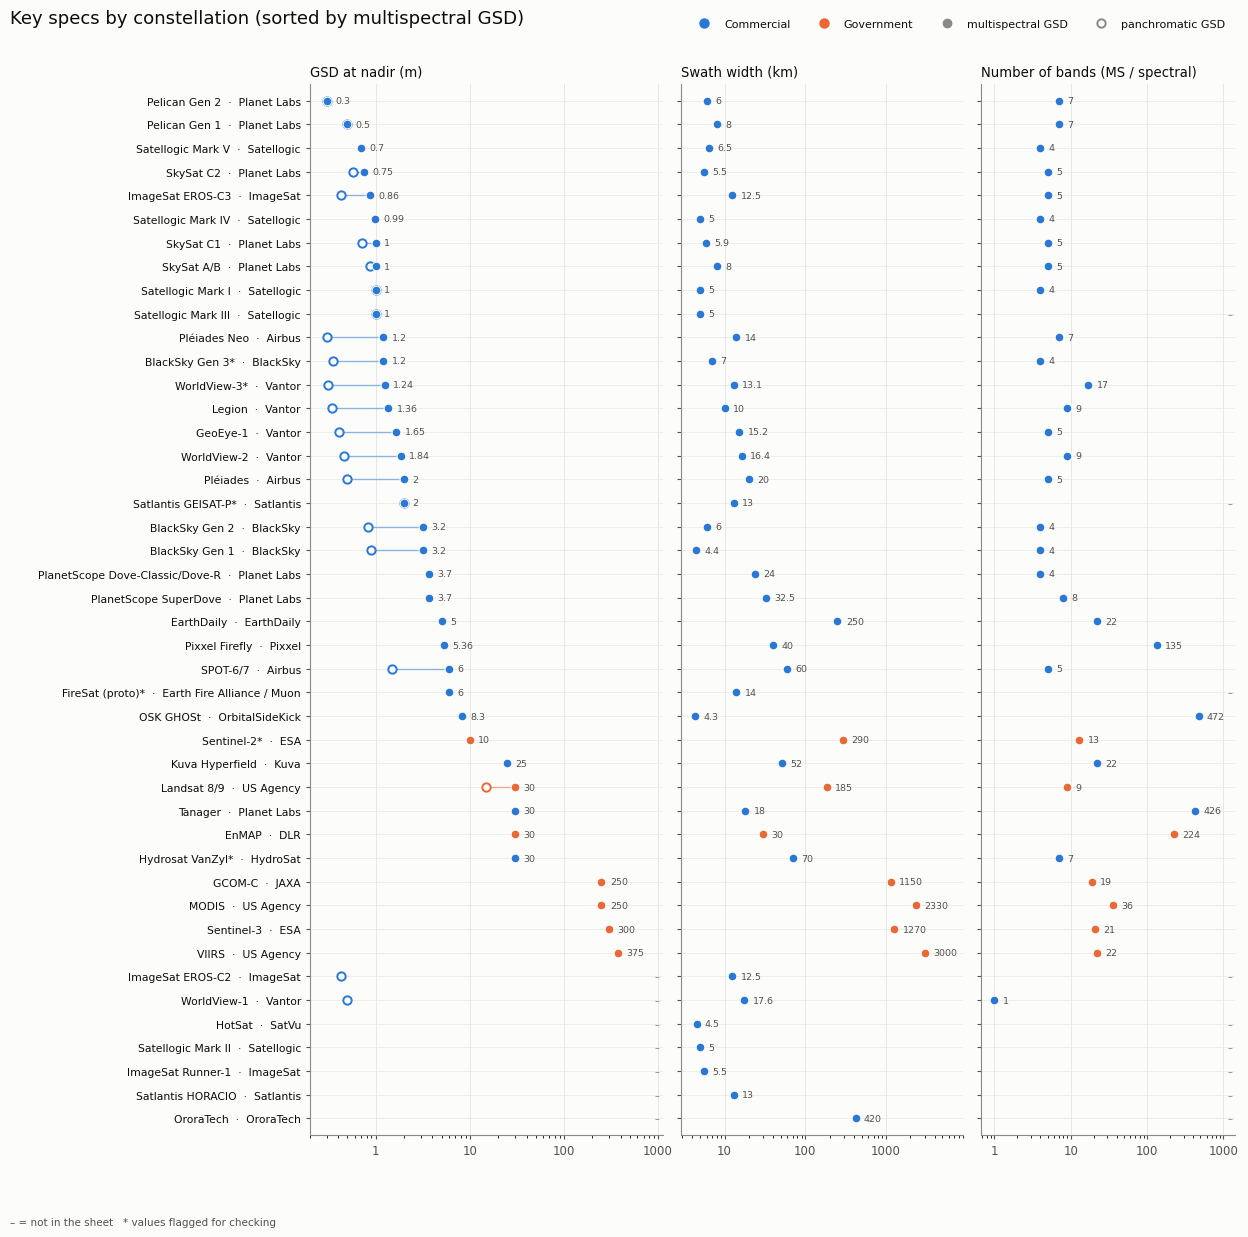

In [10]:
fig = vs.plot_spec_strips(groups, flagged=FLAGGED)
fig.savefig(OUT_DIR / 'specs_strips.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())

### Cross-track swath width

Nominal image footprints (square of side = swath width) at true scale: every panel has the same km extent, so square sizes compare directly. The wide-swath government sensors are listed
under the figure instead (they would fill many panels).

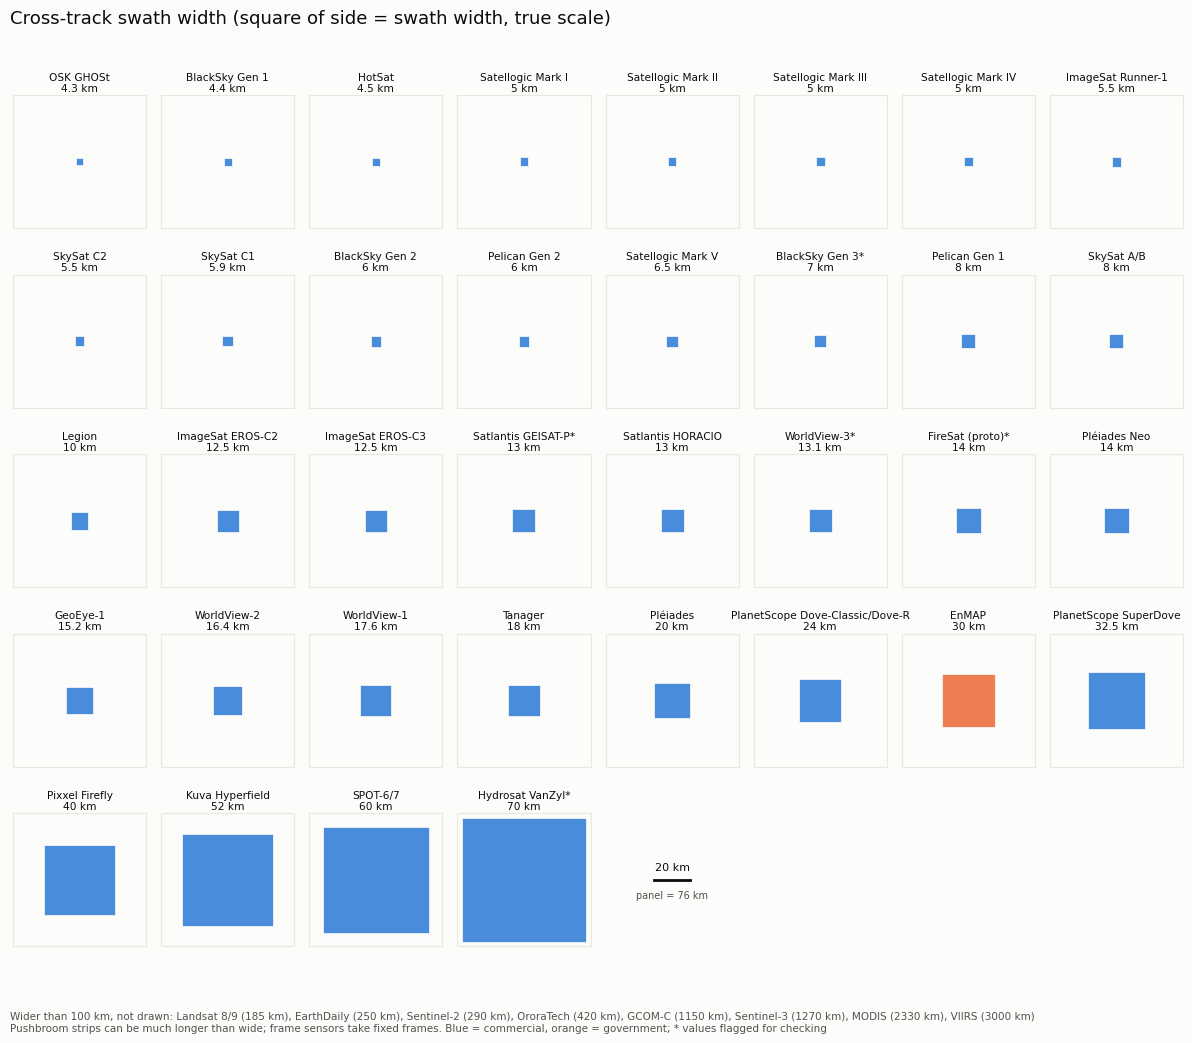

In [11]:
fig = vs.plot_footprints(groups, max_swath_km=100, flagged=FLAGGED)
fig.savefig(OUT_DIR / 'specs_footprints.png', dpi=DPI, bbox_inches='tight', facecolor=fig.get_facecolor())

## 6. Revisit time at 0°, 40° and 60° latitude

The sheet's *Revisit Time* mixes definitions (vendor figures at full agility, one satellite's repeat cycle), so revisit is
**simulated** from each orbit instead: a year of passes over sites on 36 longitudes at each latitude. A pass counts when the
site is within reach (half the swath, plus the agility for satellites that point), within the view-angle limit, and the
sun is at least `SUN_MIN_DEG` high. Revisit = 1 / passes per day, with a constellation's satellites spread evenly.

| latitude | why |
|---|---|
| 0° | worst case for sun-synchronous orbits; the tropics |
| 40°N | where our radiometric sites are (23°S to 46°N) and where vendors quote revisit; mid-inclination orbits do best here |
| 60°N | boreal; mid-inclination orbits (Legion 3–6, EROS-C3) cannot reach it |

Two views: **≤ `REVISIT_CAP_DEG`° off nadir** (radiometric quality) and **full agility** (what vendor figures assume). Two
seasons: whole year and June–August (at 60°N the winter sun is too low). Inclination is not in the sheet: sun-synchronous
rows get it from the altitude, others from `vs.ORBIT_INCLINATION`. Tasked satellites with no agility in the sheet are
assumed able to point to the limit (≤ view only). The values are mean gaps: no cloud, competing orders or duty cycle.
Takes about 2–3 minutes (one simulation per distinct orbit).

In [12]:
rv, rv_inputs = vs.revisit(raw, all_groups, cap_deg=REVISIT_CAP_DEG, sun_min_deg=SUN_MIN_DEG)
cur = rv[rv.group.isin(groups.group)]
tbl = cur[cur.season == 'year'].pivot_table(index='group', columns=['view', 'lat'], values='revisit_days', aggfunc='first')
tbl.columns = [f"{'<=' + str(REVISIT_CAP_DEG) + 'deg' if v == 'cap' else 'full agility'} {lat}N" for v, lat in tbl.columns]
tbl['sheet value'] = groups.set_index('group').revisit_days
tbl = tbl.sort_values(tbl.columns[1])
print(f"Mean revisit (days), whole year, sun >= {SUN_MIN_DEG} deg; inf = orbit never reaches the latitude, NaN = not computed")
tbl.round(2)

Mean revisit (days), whole year, sun >= 10 deg; inf = orbit never reaches the latitude, NaN = not computed


,<=20deg 0N,<=20deg 40N,<=20deg 60N,full agility 0N,full agility 40N,full agility 60N,sheet value
group,,,,,,,
VIIRS,0.31,0.23,0.17,0.31,0.23,0.17,1.0
Satellogic Mark V,0.31,0.23,0.18,0.23,0.18,0.14,1.0
Satellogic Mark IV,0.36,0.28,0.21,0.28,0.21,0.16,1.0
PlanetScope SuperDove,0.40,0.30,0.23,0.40,0.30,0.23,1.0
BlackSky Gen 2,0.41,0.31,0.24,0.14,0.11,0.08,0.1
PlanetScope Dove-Classic/Dove-R,0.55,0.41,0.32,0.55,0.41,0.32,1.0
MODIS,0.58,0.44,0.33,0.58,0.44,0.33,1.0
SkySat C1,0.60,0.46,0.35,NaN,NaN,NaN,1.0
EarthDaily,0.60,0.46,0.35,0.13,0.10,0.07,1.0


In [13]:
# Why some constellations are not computed, and what was assumed
why = cur[cur.why != ''].drop_duplicates(['group', 'view'])[['group', 'view', 'why']]
display(why)
rv_inputs.loc[rv_inputs.notes != '', ['label', 'notes']].drop_duplicates('notes')

,group,view,why
0,Pelican Gen 2,cap,"Pelican Gen 2: altitude, inclination not in the sheet"
6,Pelican Gen 2,max,"Pelican Gen 2: altitude, inclination not in the sheet"
12,Pelican Gen 1,cap,"Pelican Gen 1: altitude, inclination not in the sheet"
18,Pelican Gen 1,max,"Pelican Gen 1: altitude, inclination not in the sheet"
42,SkySat C2,max,SkySat C2: agility not in the sheet
54,ImageSat EROS-C3,max,ImageSat EROS-C3: agility not in the sheet
90,SkySat C1,max,SkySat C1: agility not in the sheet
132,BlackSky Gen 3,cap,"Global Gen 3: altitude, inclination not in the sheet"
138,BlackSky Gen 3,max,"Global Gen 3: altitude, inclination not in the sheet"
378,Kuva Hyperfield,max,Hyperfield Hyperfield-1A: agility not in the sheet


,label,notes
10,Envisat MERIS,"no agility in the sheet; wide-swath systematic mapper, so nadir-lo..."
70,ISS DESIS,number of satellites not in the sheet: 1 assumed
74,ImageSat EROS-B,'Near polar LEO' treated as sun-synchronous


### Revisit estimates into the sheet

Six columns, `Revisit est. 0° / 40°N / 60°N (days, ≤20° view)` and the same for `full agility`, plus `Revisit est. notes`
(date, settings, the satellites counted and any assumption). Whole-year values. A constellation's value goes on each of its
current rows; retired / planned rows of a current constellation get only a note. `no access` = the orbit never reaches that
latitude; empty = not computed (reason in the note). The values are kept in `specs/revisit_estimates.csv`, and
`specs/write_revisit.gs` writes them: in the sheet, Extensions > Apps Script, paste, run `previewRevisit`, then `writeRevisit`
(new columns go after the last header; one row per column in the *Edit log* tab).

In [14]:
today = pd.Timestamp.today().strftime('%Y-%m-%d')
rv_cols = vs.revisit_sheet_columns((rv, rv_inputs), all_groups, raw, date=today)
rv_cols.to_csv(REVISIT_CSV, index=False, lineterminator='\n')
print('wrote', vs.revisit_apps_script(rv_cols, REVISIT_SCRIPT, batch=f'revisit_estimates_{today}'))
heads = [h for h in rv_cols.columns if h.startswith('Revisit est.') and h != vs.REVISIT_NOTE_HEADER]
print(f"{(rv_cols[heads] != '').any(axis=1).sum()} of {len(rv_cols)} rows get values -> {REVISIT_CSV}")
rv_cols.set_index(['sheet_row', 'Constellation/Platform', 'Sensor Name'])[heads].head(12)

wrote /panfs/ccds02/home/pmontesa/code/csda_summaries/specs/write_revisit.gs
75 of 88 rows get values -> /home/pmontesa/code/csda_summaries/specs/revisit_estimates.csv


,,,"Revisit est. 0° (days, ≤20° view)","Revisit est. 40°N (days, ≤20° view)","Revisit est. 60°N (days, ≤20° view)","Revisit est. 0° (days, full agility)","Revisit est. 40°N (days, full agility)","Revisit est. 60°N (days, full agility)"
sheet_row,Constellation/Platform,Sensor Name,,,,,,
2,PleiadesNeo,PNEO3,2.92,2.22,1.71,1.2,0.91,0.7
3,PleiadesNeo,PNEO4,2.92,2.22,1.71,1.2,0.91,0.7
4,Pleiades,PHR1A,2.64,2.01,1.54,0.81,0.62,0.47
5,Pleiades,PHR1B,2.64,2.01,1.54,0.81,0.62,0.47
6,SPOT,SPOT6,5.29,4.02,3.09,1.65,1.25,0.96
7,SPOT,SPOT7,,,,,,
8,Global,Gen 1,7.79,5.93,4.59,2.71,2.06,1.6
9,Global,Gen 2,0.41,0.31,0.24,0.14,0.11,0.08
10,Global,Gen 3,,,,,,


## 7. Interactive dashboard

One HTML file with the same views, filterable by sector and status, with hover details (specs, open checks, edits
applied) for every constellation, tabs for imaging specs, coverage (swath map and revisit, section 6), launches and orbits, and a data table, plus a separate Database Quality tab (completeness, checks, the edit record). Written to
`html/vendor_specs.html` (served by GitHub Pages once committed; link it from the timeline when ready).

In [15]:
path = vs.write_dashboard(raw, all_groups, issues, log, DASHBOARD,
                          sheet_url=f'https://docs.google.com/spreadsheets/d/{SHEET_ID}/edit?gid={GID}',
                          revisit=(rv, rv_inputs))
print('wrote', path)

wrote /panfs/ccds02/home/pmontesa/code/csda_summaries/html/vendor_specs.html


## 8. Update loop with vendor documents (NASA Chat)

For one constellation at a time:

1. Run the next cell with `CONSTELLATION` set; copy the printed prompt.
2. In NASA Chat, attach the vendor documents from SharePoint and paste the prompt. The answer is CSV
   (`sensor,field,value,unit,document,page,quote`), only values the documents state.
3. Save the answer as a CSV on ADAPT (or paste it into `EXTRACTED` as text) and run the comparison cell: rows with
   `same = False` are proposed changes, with the document and page to cite in *Reference*.
4. Put the accepted changes in a CSV like `specs/public_check_2026-11-02.csv` (source = the document and page), add
   it to `EDIT_BATCHES` and re-run: they go into the edit record and every view.

In [16]:
CONSTELLATION = 'Legion'          # 'Constellation/Platform' as in the sheet
print(vs.extraction_prompt(raw, CONSTELLATION))

From the attached document(s), extract the specifications of the Legion satellites (LG-1, LG-2, LG-3, LG-4, LG-5, LG-6) for the fields below. Use only what the documents state; do not use outside knowledge and do not guess. If a value differs between satellites or generations, give one line per sensor.

Answer ONLY as CSV with this header:
sensor,field,value,unit,document,page,quote
- field: exactly as written below
- value: number or vocabulary term only (e.g. 0.34, Pushbroom, 2024-05-02)
- quote: the short text the value comes from
- leave out fields the documents do not give

Fields (unit or allowed values in [ ]; the current database value is shown for reference):
- Sensor Name  -- current: LG-1; LG-2; LG-3; LG-4; LG-5; LG-6
- Constellation/Platform  -- current: Legion
- Launch Date  [YYYY-MM-DD]  -- current: 2024-05-02; 2024-08-15; 2025-02-04
- Start Date  [YYYY-MM-DD, first usable data]  -- current: (empty)
- End Date  [YYYY-MM-DD]  -- current: (empty)
- Branded Name  -- current:

In [17]:
EXTRACTED = None                  # path to the CSV saved from NASA Chat, or the CSV text itself
if EXTRACTED:
    diff = vs.compare_extracted(raw, EXTRACTED, CONSTELLATION)
    print(f"{(~diff.same).sum()} of {len(diff)} extracted values differ from the sheet")
    display(diff)